# Figure 4c. Enrichment of neuron-initiated *cis*-signals in glial recipients

Among the *cis*-*trans* loci with disjoint initiating and recipient cell-type sets whose initiating (*cis*) set contains a neuron (Exc or Inh), the statistic for each glial type *g* is (# loci with *g* in the recipient set) / (# loci with a neuron in the recipient set). Enrichment = observed statistic / mean over 1,000 independent shuffles of cell-type labels within the *cis* and within the *trans* side (seed 42). Error bars are shuffle reference bounds, observed / 97.5% and observed / 2.5% quantiles of the null statistic (not a bootstrap CI of the estimate). One-sided empirical P = (1 + # null >= observed) / 1,001, BH-adjusted across the four glial types; *** FDR < 0.001 (the minimum attainable P with 1,000 shuffles is 0.000999).

Input: `data/Figure_4c_neuron_glia_enrichment.rds`

In [1]:
library(ggplot2)
res <- readRDS("data/Figure_4c_neuron_glia_enrichment.rds")
res

trans_glia,n_trans_glia,n_trans_neuron,n_eligible,observed_ratio,null_mean_ratio,enrichment,bound_low,bound_high,p_perm,fdr,sig
<fct>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Microglia,349,205,891,1.702439,1.103161,1.543237,1.351503,1.768199,0.000999001,0.000999001,***
Astrocyte,352,205,891,1.717073,1.212037,1.416684,1.251614,1.617753,0.000999001,0.000999001,***
Oligodendrocyte,363,205,891,1.770732,1.206511,1.467647,1.284811,1.681743,0.000999001,0.000999001,***
OPC,412,205,891,2.009756,1.268962,1.583780,1.400191,1.792651,0.000999001,0.000999001,***


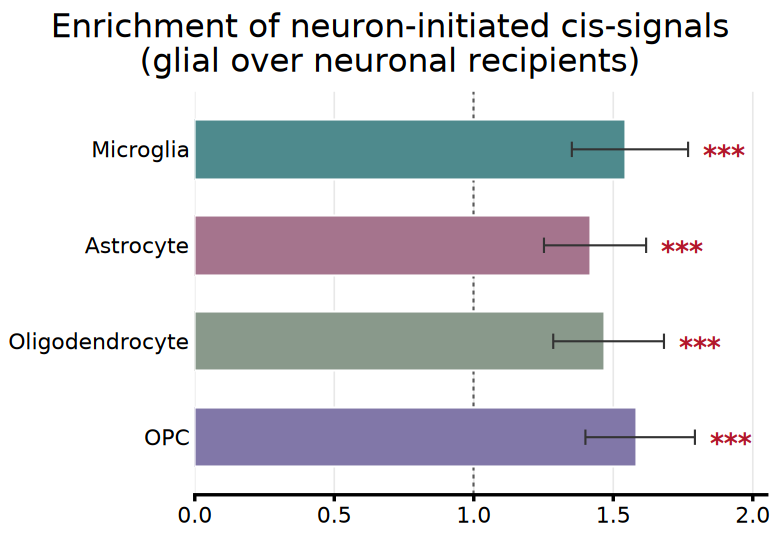

In [2]:
glia_cols <- c("Microglia" = "#4E8A8D", "Astrocyte" = "#A5748D",
               "Oligodendrocyte" = "#89998B", "OPC" = "#8177A8")
xmax <- max(res$bound_high)

p <- ggplot(res, aes(x = enrichment, y = trans_glia, fill = trans_glia)) +
  geom_vline(xintercept = 1, linetype = "dashed", colour = "grey35", linewidth = 0.45) +
  geom_col(width = 0.62, colour = "white", linewidth = 0.45) +
  geom_errorbar(aes(xmin = bound_low, xmax = bound_high), orientation = "y",
                width = 0.16, linewidth = 0.45, colour = "grey20") +
  geom_text(aes(x = bound_high + 0.03 * xmax, label = sig), hjust = 0, vjust = 0.75,
            colour = "#B2182B", fontface = "bold", size = 5.5) +
  scale_y_discrete(limits = rev(levels(res$trans_glia))) +
  scale_fill_manual(values = glia_cols, guide = "none") +
  scale_x_continuous(limits = c(0, 2.05), breaks = seq(0, 2, 0.5), expand = c(0, 0)) +
  labs(title = "Enrichment of neuron-initiated cis-signals\n(glial over neuronal recipients)",
       x = NULL, y = NULL) +
  theme_classic(base_size = 16) +
  theme(plot.title = element_text(hjust = 0.5), plot.title.position = "plot",
        axis.line.y = element_blank(), axis.ticks.y = element_blank(),
        panel.grid.major.x = element_line(colour = "grey91", linewidth = 0.35))

options(repr.plot.width = 6.5, repr.plot.height = 4.5)
p